# Task 2

---

## Predictive modeling of customer bookings

This Jupyter notebook includes some code to get you started with this predictive modeling task. We will use various packages for data manipulation, feature engineering and machine learning.

### Exploratory data analysis

First, we must explore the data in order to better understand what we have and the statistical properties of the dataset.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


The `.head()` method allows us to view the first 5 rows in the dataset, this is useful for visual inspection of our columns

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  str    
 2   trip_type              50000 non-null  str    
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  str    
 7   route                  50000 non-null  str    
 8   booking_origin         50000 non-null  str    
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), str(5)
memory usage: 5.3 MB


The `.info()` method gives us a data description, telling us the names of the columns, their data types and how many null values we have. Fortunately, we have no null values. It looks like some of these columns should be converted into different data types, e.g. flight_day.

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

In [4]:
df["flight_day"].unique()

<StringArray>
['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri']
Length: 7, dtype: str

In [5]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [6]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5])

In [7]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


The `.describe()` method gives us a summary of descriptive statistics over the entire dataset (only works for numeric columns). This gives us a quick overview of a few things such as the mean, min, max and overall distribution of each column.

From this point, you should continue exploring the dataset with some visualisations and other metrics that you think may be useful. Then, you should prepare your dataset for predictive modelling. Finally, you should train your machine learning model, evaluate it with performance metrics and output visualisations for the contributing variables. All of this analysis should be summarised in your single slide.

## 1. Further exploration

Check duplicates, the class balance of the target, and how the booking rate changes with key variables.

In [8]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Rows after removing duplicates:', len(df))
print('\nBooking completion rate:')
print(df['booking_complete'].value_counts(normalize=True).round(3))

Duplicate rows: 719
Rows after removing duplicates: 49281

Booking completion rate:
booking_complete
0    0.85
1    0.15
Name: proportion, dtype: float64


Only about 15% of customers complete a booking, so the target is **imbalanced**. Accuracy alone would be misleading (predicting 'no booking' for everyone gives ~85%), so we will also look at precision, recall, F1 and ROC-AUC.

In [9]:
top_origins = (df.groupby('booking_origin')['booking_complete']
               .agg(customers='count', booking_rate='mean')
               .sort_values('customers', ascending=False).head(8))
top_origins.round(3)

,customers,booking_rate
booking_origin,,
Australia,17691,0.051
Malaysia,7055,0.345
South Korea,4502,0.102
Japan,3819,0.124
China,3284,0.208
Indonesia,2317,0.263
Taiwan,2042,0.108
Thailand,1993,0.233


In [10]:
lead_bands = pd.cut(df['purchase_lead'], [-1, 7, 30, 90, 1000], labels=['0-7 days','8-30 days','31-90 days','90+ days'])
df.groupby(lead_bands, observed=True)['booking_complete'].mean().round(3)

purchase_lead
0-7 days      0.173
8-30 days     0.161
31-90 days    0.146
90+ days      0.138
Name: booking_complete, dtype: float64

In [11]:
df.groupby('sales_channel')['booking_complete'].mean().round(3)

sales_channel
Internet    0.155
Mobile      0.110
Name: booking_complete, dtype: float64

## 2. Feature engineering

- `is_weekend`: flight departs on Saturday or Sunday
- `total_extras`: number of extras requested (baggage + seat + meals)
- `origin_airport` / `dest_airport`: split from `route`
- High-cardinality text columns (`route`, `booking_origin`, airports) are **frequency-encoded** (replaced by how often they appear), which keeps one column per variable so feature importances are easy to read
- `sales_channel` and `trip_type` are one-hot encoded

In [12]:
import numpy as np

data = df.copy()
data['is_weekend'] = (data['flight_day'] >= 6).astype(int)
data['total_extras'] = data['wants_extra_baggage'] + data['wants_preferred_seat'] + data['wants_in_flight_meals']
data['origin_airport'] = data['route'].str[:3]
data['dest_airport'] = data['route'].str[3:]

for col in ['route', 'booking_origin', 'origin_airport', 'dest_airport']:
    data[col + '_freq'] = data[col].map(data[col].value_counts())
    data = data.drop(columns=col)

data = pd.get_dummies(data, columns=['sales_channel', 'trip_type'], drop_first=True, dtype=int)

X = data.drop(columns='booking_complete')
y = data['booking_complete']
print(X.shape)
X.head()

(49281, 18)


,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,is_weekend,total_extras,route_freq,booking_origin_freq,origin_airport_freq,dest_airport_freq,sales_channel_Mobile,trip_type_OneWay,trip_type_RoundTrip
0,2,262,19,7,6,1,0,0,5.52,1,1,20,1060,2788,122,0,0,1
1,1,112,20,3,6,0,0,0,5.52,1,0,20,1060,2788,122,0,0,1
2,2,243,22,17,3,1,1,0,5.52,0,2,20,1258,2788,122,0,0,1
3,1,96,31,4,6,0,0,1,5.52,1,1,20,1060,2788,122,0,0,1
4,2,68,22,15,3,1,0,1,5.52,0,2,20,1258,2788,122,0,0,1


## 3. Train a Random Forest

`class_weight='balanced'` makes the model pay more attention to the minority class (completed bookings).

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                            class_weight='balanced', random_state=42, n_jobs=-1)

## 4. Evaluate with 5-fold stratified cross-validation

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(rf, X, y, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
cv_results = pd.DataFrame({m: [scores['test_' + m].mean(), scores['test_' + m].std()]
                           for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']},
                          index=['mean', 'std']).round(3)
cv_results

,accuracy,precision,recall,f1,roc_auc
mean,0.764,0.342,0.622,0.441,0.786
std,0.003,0.005,0.005,0.005,0.002


Hold-out test set (20%) for a confusion matrix and classification report:

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))
print('Confusion matrix:\n', confusion_matrix(y_test, y_pred))
print('ROC-AUC:', round(roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]), 3))

              precision    recall  f1-score   support

           0      0.918     0.786     0.847      8379
           1      0.331     0.599     0.426      1478

    accuracy                          0.758      9857
   macro avg      0.624     0.693     0.636      9857
weighted avg      0.830     0.758     0.784      9857

Confusion matrix:
 [[6586 1793]
 [ 592  886]]


ROC-AUC: 0.776


## 5. Feature importance

In [16]:
import matplotlib.pyplot as plt

labels = {
    'booking_origin_freq': 'Booking origin', 'purchase_lead': 'Purchase lead', 'route_freq': 'Route',
    'length_of_stay': 'Length of stay', 'dest_airport_freq': 'Destination airport',
    'origin_airport_freq': 'Origin airport', 'flight_hour': 'Flight hour', 'flight_duration': 'Flight duration',
    'flight_day': 'Flight day', 'total_extras': 'Total extras', 'num_passengers': 'No. of passengers',
    'wants_extra_baggage': 'Extra baggage', 'sales_channel_Mobile': 'Mobile channel',
    'wants_preferred_seat': 'Preferred seat', 'wants_in_flight_meals': 'In-flight meals',
    'is_weekend': 'Weekend flight', 'trip_type_RoundTrip': 'Round trip', 'trip_type_OneWay': 'One way'}
importances = pd.Series(rf.feature_importances_, index=X.columns).rename(labels).sort_values()
importances.sort_values(ascending=False).round(3)

Booking origin         0.217
Purchase lead          0.111
Route                  0.108
Length of stay         0.099
Destination airport    0.089
Origin airport         0.086
Flight hour            0.077
Flight duration        0.055
Flight day             0.048
Total extras           0.026
No. of passengers      0.025
Extra baggage          0.016
Mobile channel         0.013
Preferred seat         0.012
In-flight meals        0.011
Weekend flight         0.009
Round trip             0.001
One way                0.000
dtype: float64

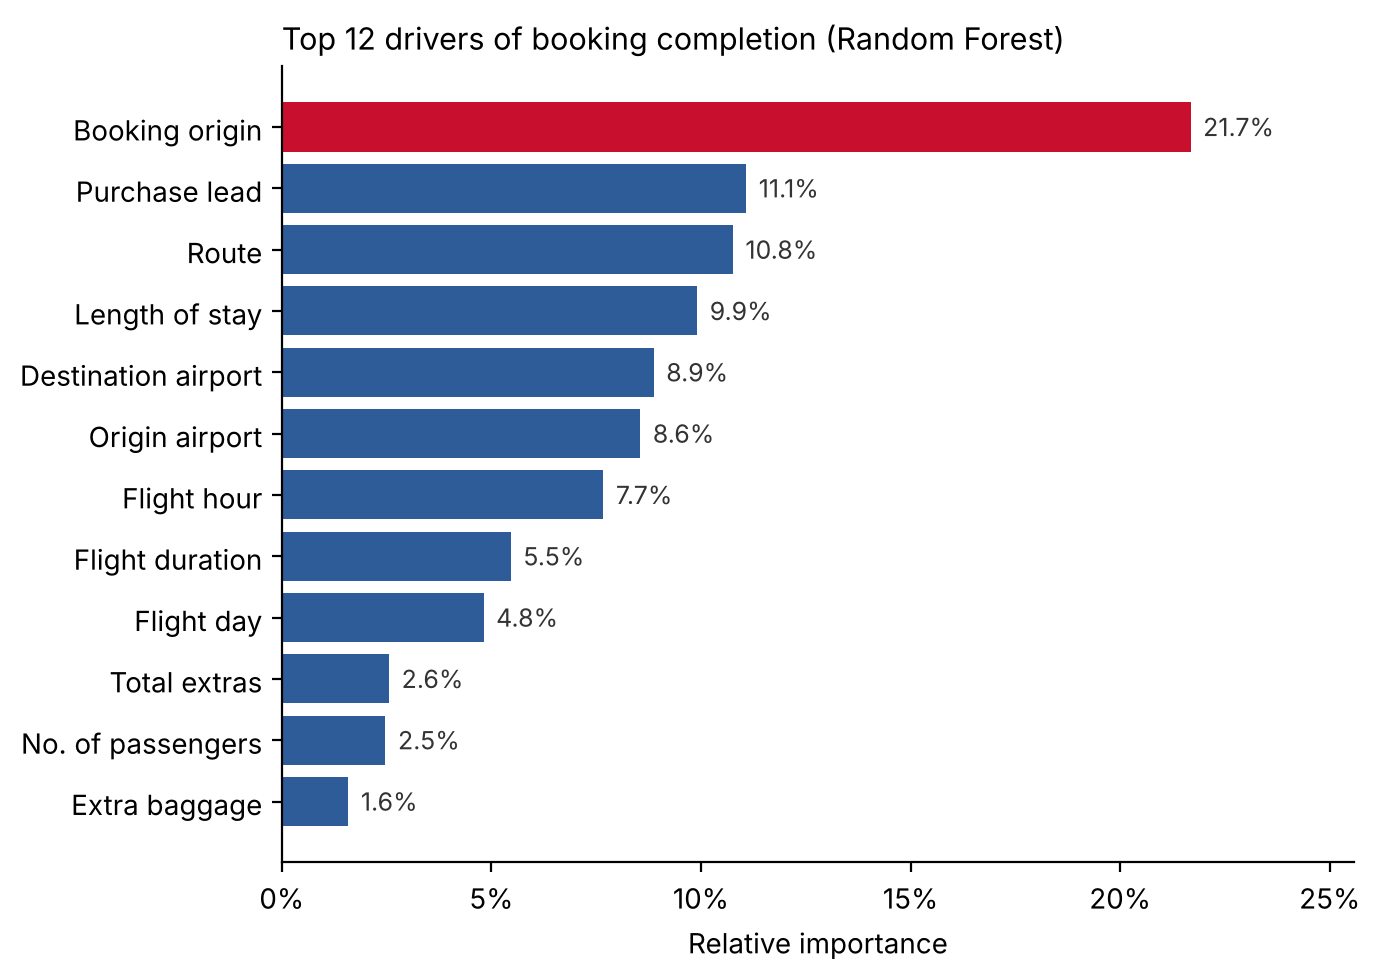

In [17]:
top = importances.tail(12)
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#2E5C99'] * len(top)
colors[-1] = '#C8102E'
ax.barh(top.index, top.values, color=colors)
for i, v in enumerate(top.values):
    ax.text(v + 0.003, i, f'{v:.1%}', va='center', fontsize=9, color='#333333')
ax.set_xlabel('Relative importance')
ax.set_xlim(0, top.max() * 1.18)
ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.set_title('Top 12 drivers of booking completion (Random Forest)', fontsize=11, loc='left')
plt.tight_layout()
plt.savefig('../output/feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Summary

- **Booking origin** is the strongest driver: completion rates vary widely by country (e.g. ~35% for Malaysia vs ~5% for Australia).
- **Purchase lead, route and length of stay** follow; customers booking closer to departure complete more often.
- Ancillary choices (baggage, seat, meals), trip type and weekend flights add little predictive power.
- Cross-validated ROC-AUC ≈ 0.79: the data is moderately predictive. Recall of ~62% for bookers means the model finds most likely buyers, but low precision (~34%) means many false positives.
- **Next step:** add richer behavioural data (e.g. browsing/session history, price, past bookings), tune the model, and test a gradient-boosting model to improve precision.